# Model B, B0b (crossing style) and B2 (try-and-keep) (Oct 30, 2026)

**Spec (descriptive only; given before results):**

TASK: Model B data checks B0b (crossing style) and B2 (try-and-keep). Descriptive only.
G-train only (G-val stays clean). Never load Ring/CT. No simulation; no edits to existing
src/slider files (new helper files are fine). Same runs, human seats and step/stop
definitions as B0 (src/slider/stop_states.py, motion.py F1b). Player = (group, seat).

PART 1 - B0b: is crossing style a player trait?
- Completed crossing = an outbound segment reaching the opposite end band (as in B0). smooth = no stop at all.
- Per interface (lab v09, old CL, CC):
  - a) smooth share, and the stop chance per step in non-smooth crossings (expected ~0.5);
  - b) per player with >= 3 completed crossings: their smooth share. Histogram per interface
    (results/figures/pB0b_player_smooth.png), with the curve expected under one common pi overlaid;
  - c) trait test: SD of the player smooth shares vs. the same SD after shuffling crossings
    across players within interface (1,000 permutations, seed 573) -> p-value. Also a
    beta-binomial fit: mean pi and overdispersion rho, with 95% CIs;
  - d) context, descriptive: smooth share by A at crossing start (A <= 0.5 vs. > 0.5), by
    topology, and by round number within the session (1-3 vs. later).
- Table: results/tables/pB0b_crossing_style.csv.

PART 2 - B2: do players keep a tentative step when their Agreement rises?
- try = the first step against the current direction phi, taken from a steady state
  (moving, halted after the first move, or at the wall) = the first step of an event the
  m = 2 detector labels a reversal or a probe.
  kept = it became a reversal; undone = it became a probe; unresolved -> excluded.
- For each try:
  - hold = time from the try step to the player's next own step;
  - dA = (A at the row just before that next own step) - (A at the last row strictly before the try);
  - dA_own = the change due to the player's own step only (neighbors held at their pre-try positions);
  - others_moved = 1 if any neighbor stepped during the hold.
  - Flag tries whose next own step is in the same row, or with hold < 0.2 s, as "no time to read A".
- Per interface, and split by topology (Hierarchy / Full / Star):
  P(kept | dA > 0), P(kept | dA = 0), P(kept | dA < 0), with group-bootstrap 95% CIs
  (1,000, stratified by dataset, seed 573):
  (i) all tries; (ii) only tries with hold >= 0.2 s (time to react); (iii) by the sign of dA_own instead of dA.
- Also report: the share of tries with "no time to read A"; the share with others_moved;
  and P(kept) for tries from the wall vs. mid-slider.
- Figure: P(kept) vs. dA in bins (results/figures/pB2_keep_by_dA.png), one panel per interface, for set (ii).
- Table: results/tables/pB2_try_keep.csv.

NOTEBOOK: notebooks/path1/pB0b_pB2.ipynb (spec cell first, short cells, a 2-3 line "how to
read it" under each table and figure). Execute, add a one-line README entry, commit.

## Choices the spec leaves open

Fixed in `src/slider/model_b.py` (a new file; no existing file changed) before any table was made.

**B0b**
- **Crossings** come from the B0 step table (`stop_states.step_table`): completed outbound segments with at least one counted step. steps / stops = the segment's counted moving steps / stops.
- **A at crossing start** = the player's A at the row before the step that leaves the band (A in [0, 1]; every seat, bots too).
- **Round number** = `wave` (the round's place in the file's play order; rounds not loaded still count).
- **Trait test:** only players with >= 3 crossings; the smooth labels of their crossings are shuffled across them within interface (pooled: within each interface, SD over all players). p = (1 + number of permuted SDs >= observed) / 1,001. The 2.5 / 97.5% points of the permuted SDs are in ci_low / ci_high of that row.
- **Beta-binomial:** maximum likelihood on the same players (smooth crossings of n), rho = 1 / (a + b + 1). 95% CI: refits on 1,000 group resamples (files within dataset, seed 573, the draws of `motion.boot_ratios`). Per interface only: a pooled fit would mix three different pi.
- **Expected curve under one pi:** pi = the interface's smooth share over these players; each player's share ~ Binomial(n_i, pi) / n_i, summed over players into the same 0.1 bins.
- **CIs of shares and chances:** `motion.boot_ratios` (1,000, seed 573), as in B0.

**B2**
- **Tries** = every event of `detect_events(m = 2)` on the seat's path (the t = 0, s = 0 row first, as in motion.py) that is not unresolved. A new event opens only when no other is open, so its first step is always from a steady state. On old CL the detector works on k = round(10 s), so a try is the step that changes k.
- **Next own step** = the next row where the seat's s changes (motion.py's own steps; on old CL a 0.02 step). If there is none, the hold runs to round_end and dA uses the last row.
- **"Next own step in the same row"**: one row cannot hold two own steps, so this is read as a try whose own row already makes m = 2 steps against the direction (a jump that is a reversal at once). no_time = that, or hold < 0.2 s.
- **others_moved** = some network neighbor (bots too) changes s between the row before the try and the row before the next own step (the window of dA).
- **From the wall** = |k| = 10 on the row before the try. On lab and CC this is |s| = 1 (checked below); on old CL the k grid puts the try a few 0.02 steps off the wall, so |s| = 1 would count none.
- **Sign of dA** with a tolerance of 1e-9.
- **(iii)** uses all tries (set i). The pooled rows draw all 39 groups.
- **Figure:** dA in 9 fixed bins; bins with fewer than 30 tries are not drawn.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from slider import config, model_b, motion, stop_states
from slider import slider_logs as sl

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

runs, table = sl.load_runs("behavior")                  # roles={"train"}: G-train only, no G-val, Ring or CT
assert set(table["role"]) == {"train"}
steps = stop_states.step_table(runs)
cross = model_b.crossing_table(runs, steps).assign(one=1)
tries = model_b.try_table(runs).assign(one=1)
print(len(runs), "rounds,", table["file"].nunique(), "groups,", len(cross), "completed crossings,", len(tries), "tries")

244 rounds, 39 groups, 3033 completed crossings, 7718 tries


In [2]:
def boot_cells(d, cells, n_boot=1000):
    """cells: dicts with labels and mask, num, den. Estimate = sum(num) / sum(den) over the mask, with the
    95% CI of motion.boot_ratios (groups within dataset, seed 573)."""
    cols = {}
    for i, c in enumerate(cells):
        mask = np.asarray(c["mask"], float)
        cols[f"y{i}"] = d[c["num"]].to_numpy(float) * mask
        cols[f"n{i}"] = d[c["den"]].to_numpy(float) * mask
    x = pd.concat([d[["file", "dataset"]], pd.DataFrame(cols, index=d.index)], axis=1)
    with np.errstate(invalid="ignore", divide="ignore"):
        low, high = motion.boot_ratios(x, [(f"y{i}", f"n{i}") for i in range(len(cells))], n_boot)
    out = []
    for i, c in enumerate(cells):
        n, y = x[f"n{i}"].sum(), x[f"y{i}"].sum()
        out.append({**{k: v for k, v in c.items() if k not in ("mask", "num", "den")}, "n": int(n), "events": int(y),
                    "estimate": y / n if n else np.nan, "ci_low": low[i], "ci_high": high[i]})
    return out


def pooled(name):
    return "pooled" if name == "shared" else name

# Part 1 — B0b: is crossing style a player trait?
## a) Smooth share; stop chance per step in non-smooth crossings; d) context

In [3]:
def style_cells(d):
    ones = np.ones(len(d), bool)
    cells = [{"section": "a) all crossings", "cell": "smooth share", "mask": ones, "num": "smooth", "den": "one"},
             {"section": "a) all crossings", "cell": "stop chance per step, non-smooth crossings",
              "mask": d["smooth"] == 0, "num": "stops", "den": "steps"},
             {"section": "d) A at crossing start", "cell": "A <= 0.5", "mask": d["A_start"] <= 0.5},
             {"section": "d) A at crossing start", "cell": "A > 0.5", "mask": d["A_start"] > 0.5}]
    cells += [{"section": "d) topology", "cell": top, "mask": d["topology"] == top} for top in ["Hierarchy", "Full", "Star"]]
    cells += [{"section": "d) round in session", "cell": "rounds 1-3", "mask": d["wave"] <= 3},
              {"section": "d) round in session", "cell": "rounds 4+", "mask": d["wave"] > 3}]
    return [{"num": "smooth", "den": "one", **c} for c in cells]


style = pd.DataFrame([{"interface": pooled(name), **r} for name, d in motion.by_interface(cross)
                      for r in boot_cells(d, style_cells(d))])
style = style[style["n"] > 0]
style.round(4)

,interface,section,cell,n,events,estimate,ci_low,ci_high
0,lab_v09,a) all crossings,smooth share,1267,557,0.4396,0.3947,0.4881
1,lab_v09,a) all crossings,"stop chance per step, non-smooth crossings",11756,5482,0.4663,0.3997,0.5256
2,lab_v09,d) A at crossing start,A <= 0.5,1100,493,0.4482,0.4044,0.4964
3,lab_v09,d) A at crossing start,A > 0.5,167,64,0.3832,0.3101,0.4609
4,lab_v09,d) topology,Hierarchy,718,366,0.5097,0.4542,0.5634
5,lab_v09,d) topology,Full,549,191,0.3479,0.2708,0.4361
7,lab_v09,d) round in session,rounds 1-3,723,271,0.3748,0.3096,0.4491
8,lab_v09,d) round in session,rounds 4+,544,286,0.5257,0.4711,0.5752
9,old_cl,a) all crossings,smooth share,101,24,0.2376,0.1471,0.4242
10,old_cl,a) all crossings,"stop chance per step, non-smooth crossings",7032,977,0.1389,0.1121,0.2233


## b) Player smooth shares (players with >= 3 completed crossings)

In [4]:
players = model_b.player_shares(cross)
players["share"] = players["smooth"] / players["n"]
EDGES = np.linspace(0, 1, 11)


def expected_counts(p, pi):
    """Expected number of players per 0.1 bin of the smooth share if every player has the same pi."""
    out = np.zeros(10)
    for n in p["n"]:
        k = np.arange(n + 1)
        np.add.at(out, np.minimum((k / n * 10 + 1e-9).astype(int), 9), stats.binom.pmf(k, n, pi))
    return out


players.groupby("interface").agg(players=("n", "size"), crossings=("n", "sum"), median_n=("n", "median"),
                                 mean_share=("share", "mean"), sd_share=("share", "std")).loc[motion.INTERFACES].round(3)

,players,crossings,median_n,mean_share,sd_share
interface,,,,,
lab_v09,108,1230,9.0,0.421,0.268
old_cl,14,101,6.0,0.320,0.332
cc,104,1652,14.0,0.395,0.336


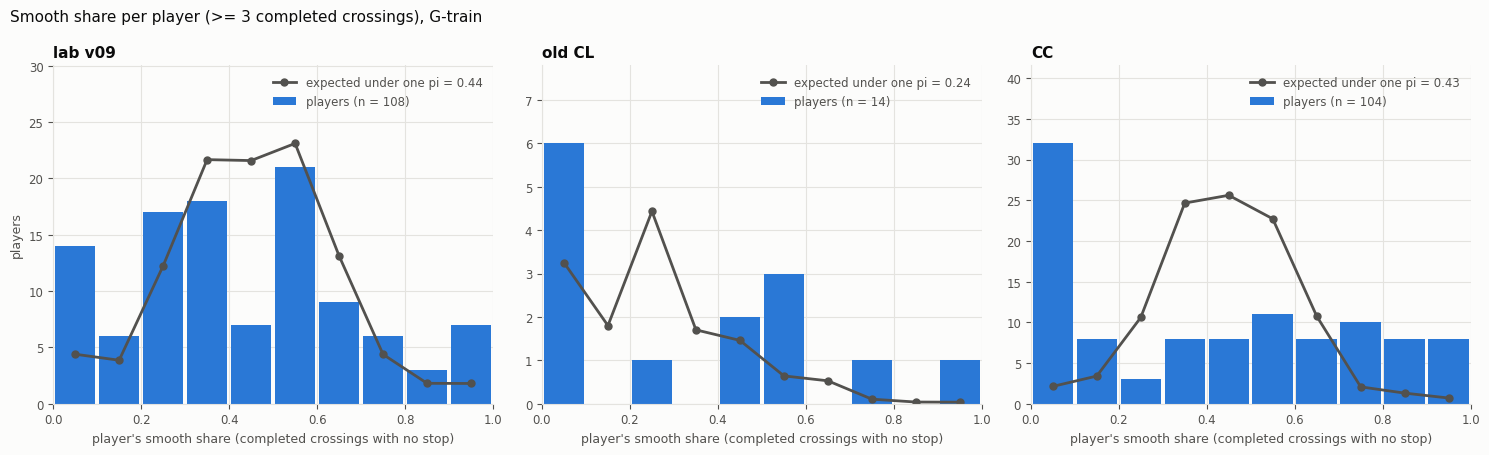

In [5]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
NAMES = {"lab_v09": "lab v09", "old_cl": "old CL", "cc": "CC"}


def style_axes(ax, title):
    ax.set_title(title, loc="left", fontsize=11, color=INK, fontweight="bold")
    ax.set_facecolor(SURFACE)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=8.5)


fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), facecolor=SURFACE)
for ax, name in zip(axes, motion.INTERFACES):
    p = players[players["interface"] == name]
    pi = p["smooth"].sum() / p["n"].sum()
    obs = np.histogram(np.minimum(p["share"], 0.9999), EDGES)[0]
    mids = EDGES[:-1] + 0.05
    ax.bar(mids, obs, width=0.1 - 0.008, color=BLUE, label=f"players (n = {len(p)})")
    exp = expected_counts(p, pi)
    ax.plot(mids, exp, color=INK_2, linewidth=2, marker="o", markersize=5, label=f"expected under one pi = {pi:.2f}")
    ax.set_ylim(0, 1.3 * max(obs.max(), exp.max()))
    style_axes(ax, NAMES[name])
    ax.set_xlim(0, 1)
    ax.set_xlabel("player's smooth share (completed crossings with no stop)", color=INK_2, fontsize=9)
    ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper right")
axes[0].set_ylabel("players", color=INK_2, fontsize=9)
fig.suptitle("Smooth share per player (>= 3 completed crossings), G-train", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(config.FIGURES / "pB0b_player_smooth.png", dpi=150, facecolor=SURFACE)
plt.show()

**How to read it.** Bars: players by their own smooth share. Dots: how many players each bin would hold if all players shared one smooth chance pi and differed only by luck (each player keeps their own number of crossings). Bars spread wider than the dots (more players near 0 and near 1) point to a player trait.

## c) Trait test: permutation SD and beta-binomial

In [6]:
trait = []
for name, p in motion.by_interface(players):
    sd, perm = model_b.permutation_sd(cross, p)
    trait.append({"interface": pooled(name), "section": "c) trait test", "cell": "SD of player smooth shares",
                  "n": len(p), "events": int(p["n"].sum()), "estimate": sd,
                  "ci_low": np.percentile(perm, 2.5), "ci_high": np.percentile(perm, 97.5),
                  "perm_mean": perm.mean(), "p_value": (1 + (perm >= sd).sum()) / (1 + len(perm))})
    if name == "shared":
        continue
    fit = model_b.betabinom_fit(p["smooth"].to_numpy(), p["n"].to_numpy())
    low, high = model_b.boot_groups(p, lambda d: model_b.betabinom_fit(d["smooth"].to_numpy(), d["n"].to_numpy()))
    for i, par in enumerate(["pi", "rho"]):
        trait.append({"interface": name, "section": "c) beta-binomial", "cell": par, "n": len(p),
                      "events": int(p["n"].sum()), "estimate": fit[i], "ci_low": low[i], "ci_high": high[i]})
trait = pd.DataFrame(trait)
trait.round(4)

,interface,section,cell,n,events,estimate,ci_low,ci_high,perm_mean,p_value
0,lab_v09,c) trait test,SD of player smooth shares,108,1230,0.2678,0.1614,0.2150,0.1880,0.001
1,lab_v09,c) beta-binomial,pi,108,1230,0.4286,0.3814,0.4780,NaN,NaN
2,lab_v09,c) beta-binomial,rho,108,1230,0.1819,0.1034,0.2689,NaN,NaN
3,old_cl,c) trait test,SD of player smooth shares,14,101,0.3317,0.1137,0.2554,0.1786,0.001
4,old_cl,c) beta-binomial,pi,14,101,0.2841,0.1667,0.4304,NaN,NaN
5,old_cl,c) beta-binomial,rho,14,101,0.4000,0.2127,0.4000,NaN,NaN
6,cc,c) trait test,SD of player smooth shares,104,1652,0.3358,0.1328,0.1792,0.1559,0.001
7,cc,c) beta-binomial,pi,104,1652,0.3783,0.3377,0.4216,NaN,NaN
8,cc,c) beta-binomial,rho,104,1652,0.4161,0.3627,0.4701,NaN,NaN
9,pooled,c) trait test,SD of player smooth shares,226,2983,0.3045,0.1623,0.1958,0.1795,0.001


In [7]:
b0b = pd.concat([style, trait], ignore_index=True)
order = {"lab_v09": 0, "old_cl": 1, "cc": 2, "pooled": 3}
b0b = b0b.sort_values("interface", key=lambda s: s.map(order), kind="stable")
b0b.to_csv(config.TABLES / "pB0b_crossing_style.csv", index=False)
b0b.drop(columns="section").round(4)

,interface,cell,n,events,estimate,ci_low,ci_high,perm_mean,p_value
0,lab_v09,smooth share,1267,557,0.4396,0.3947,0.4881,NaN,NaN
1,lab_v09,"stop chance per step, non-smooth crossings",11756,5482,0.4663,0.3997,0.5256,NaN,NaN
2,lab_v09,A <= 0.5,1100,493,0.4482,0.4044,0.4964,NaN,NaN
3,lab_v09,A > 0.5,167,64,0.3832,0.3101,0.4609,NaN,NaN
4,lab_v09,Hierarchy,718,366,0.5097,0.4542,0.5634,NaN,NaN
5,lab_v09,Full,549,191,0.3479,0.2708,0.4361,NaN,NaN
6,lab_v09,rounds 1-3,723,271,0.3748,0.3096,0.4491,NaN,NaN
7,lab_v09,rounds 4+,544,286,0.5257,0.4711,0.5752,NaN,NaN
34,lab_v09,SD of player smooth shares,108,1230,0.2678,0.1614,0.2150,0.1880,0.001
35,lab_v09,pi,108,1230,0.4286,0.3814,0.4780,NaN,NaN


**How to read it.** n = crossings (players for the trait rows; steps for the per-step stop chance), events = smooth crossings (stops). For the SD row, ci_low / ci_high are the middle 95% of the SDs after shuffling crossings across players, and p_value says how often a shuffle gives an SD at least as large as the observed one. rho = 0 means one pi for all players; larger rho means players differ.

# Part 2 — B2: do players keep a tentative step when their Agreement rises?
## The tries

In [8]:
lab_cc = tries["interface"] != "old_cl"                 # check: from the wall = |s| = 1 on lab and CC
assert (tries.loc[lab_cc, "from_wall"] == np.isclose(tries.loc[lab_cc, "s_before"].abs(), 1)).all()
tries["no_time"] = ((tries["same_row"] == 1) | (tries["hold"] < 0.2)).astype(int)
tries["sign_dA"] = model_b.sign_label(tries["dA"])
tries["sign_dA_own"] = model_b.sign_label(tries["dA_own"])
tries.groupby("interface").agg(tries=("one", "size"), kept=("kept", "mean"), same_row=("same_row", "mean"),
                               no_time=("no_time", "mean"), others_moved=("others_moved", "mean"),
                               from_wall=("from_wall", "mean"), median_hold=("hold", "median")).loc[motion.INTERFACES].round(3)

,tries,kept,same_row,no_time,others_moved,from_wall,median_hold
interface,,,,,,,
lab_v09,3638,0.795,0.009,0.138,0.573,0.644,0.500
old_cl,456,0.796,0.000,0.645,0.746,0.489,0.100
cc,3624,0.792,0.015,0.119,0.512,0.721,0.498


## P(kept) by the sign of dA (and dA_own), per interface and topology

In [9]:
SETS = {"(i) all tries": lambda d: np.ones(len(d), bool), "(ii) hold >= 0.2 s": lambda d: d["no_time"] == 0}


def keep_cells(d):
    cells = [{"topology": "all", "section": "context", "cell": c, "mask": m, "num": num}
             for c, m, num in [("P(kept), all tries", np.ones(len(d), bool), "kept"),
                               ("share with no time to read A", np.ones(len(d), bool), "no_time"),
                               ("share with others_moved", np.ones(len(d), bool), "others_moved"),
                               ("P(kept), from the wall", d["from_wall"] == 1, "kept"),
                               ("P(kept), mid-slider", d["from_wall"] == 0, "kept")]]
    for top in ["all", "Hierarchy", "Full", "Star"]:
        t = np.ones(len(d), bool) if top == "all" else d["topology"] == top
        for sign in ["> 0", "= 0", "< 0"]:
            for name, f in SETS.items():
                cells.append({"topology": top, "section": name, "cell": f"P(kept | dA {sign})",
                              "mask": t & f(d) & (d["sign_dA"] == sign), "num": "kept"})
            cells.append({"topology": top, "section": "(iii) by dA_own", "cell": f"P(kept | dA_own {sign})",
                          "mask": t & (d["sign_dA_own"] == sign), "num": "kept"})
    return [{"den": "one", **c} for c in cells]


b2 = pd.DataFrame([{"interface": pooled(name), **r} for name, d in motion.by_interface(tries)
                   for r in boot_cells(d, keep_cells(d))])
b2 = b2[b2["n"] > 0]
b2.to_csv(config.TABLES / "pB2_try_keep.csv", index=False)
b2[b2["topology"] == "all"].drop(columns="topology").round(4)

,interface,section,cell,n,events,estimate,ci_low,ci_high
0,lab_v09,context,"P(kept), all tries",3638,2893,0.7952,0.7475,0.8391
1,lab_v09,context,share with no time to read A,3638,503,0.1383,0.0916,0.1837
2,lab_v09,context,share with others_moved,3638,2084,0.5728,0.5219,0.6186
3,lab_v09,context,"P(kept), from the wall",2343,1806,0.7708,0.7297,0.8136
4,lab_v09,context,"P(kept), mid-slider",1295,1087,0.8394,0.7633,0.9001
5,lab_v09,(i) all tries,P(kept | dA > 0),1445,1246,0.8623,0.8108,0.9050
6,lab_v09,(ii) hold >= 0.2 s,P(kept | dA > 0),1249,1095,0.8767,0.8467,0.9076
7,lab_v09,(iii) by dA_own,P(kept | dA_own > 0),1430,1278,0.8937,0.8395,0.9374
8,lab_v09,(i) all tries,P(kept | dA = 0),418,339,0.8110,0.7152,0.8971
9,lab_v09,(ii) hold >= 0.2 s,P(kept | dA = 0),352,293,0.8324,0.7767,0.8927


**How to read it.** Each P(kept | ...) is the share of tries that became reversals (the rest were undone as probes), with the 95% group-bootstrap CI. (ii) keeps only tries where the player waited at least 0.2 s before the next own step. (iii) uses only the A change caused by the player's own try step. The context rows give the shares of tries with no time to read A and with a neighbor moving during the hold.

In [10]:
by_top = b2[b2["section"] != "context"].assign(sign=lambda d: d["cell"].str.extract(r"([<>=] 0)")[0])
by_top.pivot_table(index=["interface", "topology"], columns=["section", "sign"], values="estimate", sort=False).round(3)

section             (i) all tries (ii) hold >= 0.2 s (iii) by dA_own (i) all tries (ii) hold >= 0.2 s (iii) by dA_own (i) all tries (ii) hold >= 0.2 s (iii) by dA_own
sign                          > 0                > 0             > 0           = 0                = 0             = 0           < 0                < 0             < 0
interface topology                                                                                                                                                    
lab_v09   all               0.862              0.877           0.894         0.811              0.832             1.0         0.737              0.756           0.731
          Hierarchy         0.881              0.897           0.914         0.889              0.879             1.0         0.771              0.779           0.774
          Full              0.840              0.853           0.871         0.740              0.787             NaN         0.697              0.728           0.681
old_cl    all               0.894              0.786           0.900         0.786              0.600             1.0         0.744              0.560           0.725
          Hierarchy         0.922              0.852           0.909         0.815              0.714             1.0         0.760              0.529           0.757
          Full              0.872              0.724           0.893         0.759              0.500             NaN         0.734              0.579           0.703
cc        all               0.886              0.887           0.918         0.819              0.822             NaN         0.710              0.752           0.714
          Hierarchy         0.911              0.918           0.924         0.697              0.718             NaN         0.664              0.697           0.671
          Full              0.871              0.871           0.902         0.870              0.866             NaN         0.756              0.808           0.759
          Star              0.890              0.888           0.953         0.839              0.839             NaN         0.693              0.731           0.687
pooled    all               0.875              0.880           0.906         0.812              0.823             1.0         0.725              0.748           0.723
          Hierarchy         0.893              0.903           0.917         0.834              0.829             1.0         0.729              0.741           0.735
          Full              0.857              0.860           0.887         0.792              0.815             NaN         0.727              0.760           0.719
          Star              0.890              0.888           0.953         0.839              0.839             NaN         0.693              0.731           0.687

**By topology:** P(kept) by the sign of dA (or dA_own) per topology; estimates only, CIs in the csv. Star exists only in CC; old CL has 2 groups, so its CIs are crude.

## Figure: P(kept) vs. dA, set (ii)

In [11]:
DA_EDGES = [-np.inf, -0.1, -0.05, -0.025, -1e-9, 1e-9, 0.025, 0.05, 0.1, np.inf]
DA_LABELS = ["< -0.1", "-0.1 to -0.05", "-0.05 to -0.025", "-0.025 to 0", "0", "0 to 0.025", "0.025 to 0.05",
             "0.05 to 0.1", "> 0.1"]
react = tries[tries["no_time"] == 0].copy()
react["bin"] = pd.cut(react["dA"], DA_EDGES, labels=False)


def bin_cells(d):
    return [{"bin": b, "mask": d["bin"] == b, "num": "kept", "den": "one"} for b in range(len(DA_LABELS))]


bins = pd.DataFrame([{"interface": name, **r} for name, d in motion.by_interface(react) if name != "shared"
                     for r in boot_cells(d, bin_cells(d))])
bins.pivot_table(index="interface", columns="bin", values="n", sort=False)

bin,0,1,2,3,4,5,6,7,8
interface,,,,,,,,,
lab_v09,152.0,394.0,667.0,321.0,352.0,244.0,529.0,266.0,210.0
old_cl,4.0,2.0,20.0,65.0,15.0,44.0,10.0,1.0,1.0
cc,154.0,406.0,621.0,369.0,276.0,323.0,583.0,213.0,247.0


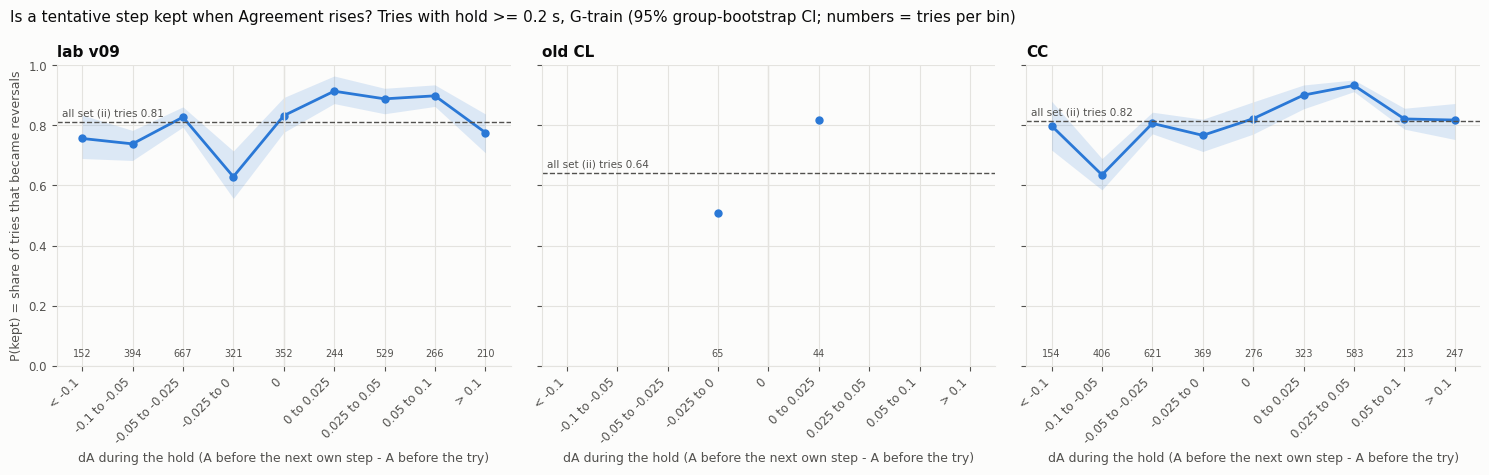

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), facecolor=SURFACE, sharey=True)
for ax, name in zip(axes, motion.INTERFACES):
    x = bins[bins["interface"] == name].copy()
    x.loc[x["n"] < 30, ["estimate", "ci_low", "ci_high"]] = np.nan            # not drawn; the line breaks there
    ax.fill_between(x["bin"], x["ci_low"], x["ci_high"], color=BLUE, alpha=0.15, linewidth=0)
    ax.plot(x["bin"], x["estimate"], color=BLUE, linewidth=2, marker="o", markersize=5)
    for r in x[x["n"] >= 30].itertuples():
        ax.annotate(f"{r.n}", (r.bin, 0.03), ha="center", fontsize=7, color=INK_2)
    avg = react.loc[react["interface"] == name, "kept"].mean()
    ax.axhline(avg, color=INK_2, linewidth=1, linestyle="--")
    ax.annotate(f"all set (ii) tries {avg:.2f}", (-0.4, avg), xytext=(0, 4), textcoords="offset points", fontsize=7.5,
                color=INK_2)
    ax.axvline(4, color=GRID, linewidth=1)
    style_axes(ax, NAMES[name])
    ax.set_xticks(range(len(DA_LABELS)), DA_LABELS, rotation=45, ha="right")
    ax.set_xlim(-0.5, len(DA_LABELS) - 0.5)
    ax.set_ylim(0, 1)
    ax.set_xlabel("dA during the hold (A before the next own step - A before the try)", color=INK_2, fontsize=9)
axes[0].set_ylabel("P(kept) = share of tries that became reversals", color=INK_2, fontsize=9)
fig.suptitle("Is a tentative step kept when Agreement rises? Tries with hold >= 0.2 s, G-train (95% group-bootstrap CI;"
             " numbers = tries per bin)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(config.FIGURES / "pB2_keep_by_dA.png", dpi=150, facecolor=SURFACE)
plt.show()

**How to read it.** Each point is the share of tries (with at least 0.2 s before the next own step) that became reversals, for tries whose Agreement changed by that much during the hold; the band is the 95% group-bootstrap CI and the small numbers are tries per bin. The dashed line is the interface's average. A rising line means players keep a step more often when their Agreement went up. Bins with fewer than 30 tries are not drawn.